# What a free video model finds in your footage, and what it misses

This notebook walks the post's result: the same text queries, the same video segments, ranked by an open model
running on your own GPU ([EmbeddingGemma 2](https://huggingface.co/google/embeddinggemma-2)) and by a hosted
video search (TwelveLabs Marengo 3.5), on three kinds of video:

1. **Vlogs and news** (QVHighlights): 90 YouTube videos of 150 s, 92 natural-language queries.
2. **A basketball broadcast** (two CC BY college games): events from the official play-by-play.
3. **A fixed traffic camera** (MEVA, CC BY 4.0): 553 timed vehicle events from 8 cameras.

**Before running it**, run the scripts in the README: the notebook reads the vectors in `index/` and the tables in
`output/`, and shows frames from `data/`. Only the last section loads the model (text only; a GPU helps, the CPU
works).

In [1]:
import json
import re
from pathlib import Path

import av
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from qvh import grow, iou, overlaps, sample

DATA, INDEX, OUT = Path("data"), Path("index"), Path("output")
QVH = sample()
QUERIES = {q["qid"]: q for q in QVH["queries"]}
MAR = np.load(INDEX / "qvh_marengo_visual.npz")
GEM = np.load(INDEX / "qvh_gemma_visual.npz")


def scores(d, q):
    """One query's scores over the segments of its own video, in time order."""
    tv = dict(zip(d["texts"].tolist(), d["text_emb"]))[q["query"]]
    rows = np.where(d["vid"] == q["vid"])[0]
    return d["start"][rows], d["end"][rows], d["emb"][rows] @ tv


def frame_at(path, t):
    with av.open(str(path)) as c:
        s = c.streams.video[0]
        c.seek(int(max(t - 1, 0) / s.time_base), stream=s)
        for f in c.decode(s):
            if f.pts * s.time_base >= t:
                return f.to_ndarray(format="rgb24")


def md_rows(path, classes, col="AP raw"):
    """{class: cell} for one column of a table written by evaluate.py."""
    lines = [l for l in Path(path).read_text().splitlines() if l.startswith("|")]
    head = [h.strip() for h in lines[0].strip("|").split("|")]
    out = {}
    for l in lines[2:]:
        cells = [c.strip() for c in l.strip("|").split("|")]
        if cells[0] in classes:
            out[cells[0]] = cells[head.index(col)]
    return out


def first(cell):
    return cell.split(" ")[0]

## 1. One query, both models

How the comparison works, on one query. Marengo cuts each video into segments where the scene changes (about 7 s
here); both models get **the same segments**, so the only difference is the model. Each segment gets a score, the
cosine between its vector and the query's vector; the top segment is the answer. It counts as a hit if it overlaps
a span the annotators marked (shaded).

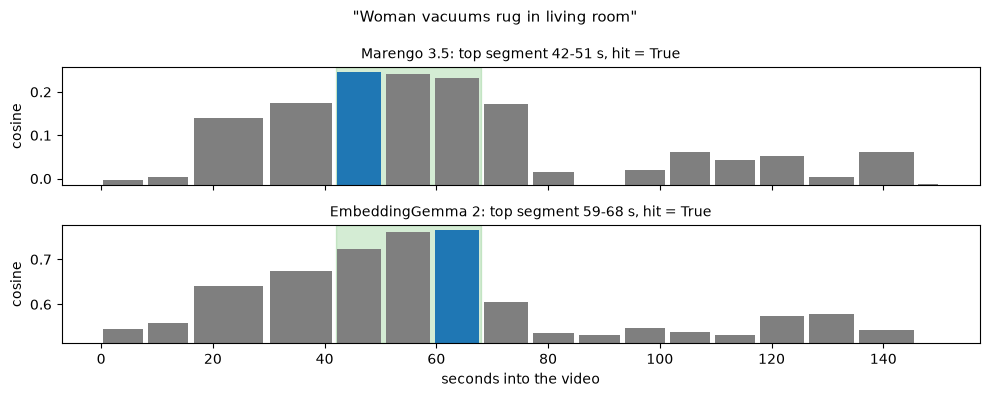

In [2]:
q = QUERIES[6266]  # "Woman vacuums rug in living room"
fig, axes = plt.subplots(2, 1, figsize=(10, 4), sharex=True)
for ax, (name, d) in zip(axes, [("Marengo 3.5", MAR), ("EmbeddingGemma 2", GEM)]):
    s, e, sc = scores(d, q)
    for a, b in q["relevant_windows"]:
        ax.axvspan(a, b, color="tab:green", alpha=0.2)
    ax.bar((s + e) / 2, sc - sc.min(), width=(e - s) * 0.9, bottom=sc.min(), color="tab:gray")
    i = int(np.argmax(sc))
    ax.bar((s[i] + e[i]) / 2, sc[i] - sc.min(), width=(e[i] - s[i]) * 0.9, bottom=sc.min(), color="tab:blue")
    ax.set_ylabel("cosine")
    ax.set_title(f"{name}: top segment {s[i]:.0f}-{e[i]:.0f} s, hit = {overlaps(s[i], e[i], q['relevant_windows'])}",
                 fontsize=10)
axes[-1].set_xlabel("seconds into the video")
fig.suptitle(f'"{q["query"]}"', fontsize=11)
plt.tight_layout()
plt.show()

The two models pick different segments (42-51 s and 59-68 s) and both are inside the annotated span (42-68 s). Note
the scales: cosines are not comparable across models, only the ranking within one video is.

## 2. Vlogs and news: 92 queries

`qvh.py evaluate` scores every query this way. AP ranks all segments of the video; Hit@1 is the top segment;
R1@0.5 grows the top segment over neighbours that score close to it and asks for an overlap of at least half (IoU)
with an annotated span. Chance comes from shuffled scores in the same video.

In [3]:
display(Markdown((OUT / "qvh_eval.md").read_text()))

# QVHighlights val sample: 92 queries, 90 videos

| model | AP | chance AP | Hit@1 | chance Hit@1 | R1@0.5 | chance R1@0.5 |
|---|---|---|---|---|---|---|
| qvh_marengo_visual | 88.7 | 34.8 | 93.5 | 34.8 | 53.3 | 4.4 |
| qvh_gemma_visual | 82.3 | 34.8 | 88.0 | 34.8 | 48.9 | 4.4 |
| hosted search, visual | | | 93.5 | | 14.1 | |
| hosted search, visual+audio | | | 94.6 | | 12.0 | |

Percent, mean over queries. Hit@1 and R1@0.5 use the top result; chance per video.


Gemma is about 5 points behind on every measure. Paired, query by query, the gap goes one way only:

In [4]:
def top1(d, q):
    s, e, sc = scores(d, q)
    i = int(np.argmax(sc))
    return float(s[i]), float(e[i]), overlaps(s[i], e[i], q["relevant_windows"])


m = np.array([top1(MAR, q)[2] for q in QVH["queries"]])
g = np.array([top1(GEM, q)[2] for q in QVH["queries"]])
print(f"both right {int((m & g).sum())}, only Marengo {int((m & ~g).sum())}, "
      f"only Gemma {int((g & ~m).sum())}, neither {int((~m & ~g).sum())}")
for q in QVH["queries"]:
    if top1(MAR, q)[2] and not top1(GEM, q)[2]:
        print(f"  only Marengo: {q['query']}")

both right 81, only Marengo 5, only Gemma 0, neither 6
  only Marengo: Young Mother have some chat with her sun
  only Marengo: Two man in matching blue sweatshirts eat mcdonalds and walk together after.
  only Marengo: Man in pink top eats fish.
  only Marengo: Man turns to talk to the camera in a parked car.


  only Marengo: Man holds up a steady cam to the mirror.


Every query Gemma misses and Marengo finds is **a person doing something specific**: eating, turning to the camera,
chatting with someone. None is a scene or an object. The clearest one:

In [5]:
q = QUERIES[5651]
video = DATA / "qvh" / f"{q['vid']}.mp4"
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, (name, d) in zip(axes, [("Marengo 3.5", MAR), ("EmbeddingGemma 2", GEM)]):
    s, e, hit = top1(d, q)
    ax.imshow(frame_at(video, (s + e) / 2))
    ax.set_title(f"{name}: {s:.0f}-{e:.0f} s, {'hit' if hit else 'miss'}", fontsize=10)
    ax.axis("off")
fig.suptitle(f'"{q["query"]}"', fontsize=11)
plt.tight_layout()
plt.show()

Gemma's pick has the man and the pink top and the fish; he is holding it on a boat, not eating it. The nouns are
right and the verb is not.

## 3. Basketball: the action is small and short

Two CC BY NCAA D-III broadcasts, Loras–Buena Vista and Misericordia–Manhattanville, with each play-by-play event
placed in the video by reading the score bug's clock (`clock_ocr.py`, `align.py`). Here the task is the other way
round: one query ("a basketball player shoots a three-pointer"), one long video, and every segment near a logged
three is a positive. Window AP at a ±5 s tolerance, chance in the last column:

In [6]:
CLASSES = ["three", "free_throw", "made_two", "foul", "turnover", "timeout"]
rows = []
for game, gem, mar in [
    ("Loras", "loras_seg-loras_marengo_visual_N8_T140_mask_d5.md", "loras-mask_marengo_visual_d5.md"),
    ("Misericordia", "misericordia_seg-misericordia-mask_marengo_visual_N8_T140_mask_d5.md",
     "misericordia-mask_marengo_visual_d5.md"),
]:
    g, mr = md_rows(OUT / gem, CLASSES), md_rows(OUT / mar, CLASSES)
    ch = md_rows(OUT / gem, CLASSES, "chance AP")
    n = md_rows(OUT / gem, CLASSES, "n")
    for c in CLASSES:
        rows.append(f"| {game} | {c} | {n[c]} | {first(g[c])} | {first(mr[c])} | {ch[c]} |")
display(Markdown("| game | class | n | Gemma | Marengo | chance |\n|---|---|---|---|---|---|\n" + "\n".join(rows)))

| game | class | n | Gemma | Marengo | chance |
|---|---|---|---|---|---|
| Loras | three | 23 | 0.11 | 0.44 | 0.09 |
| Loras | free_throw | 31 | 0.41 | 0.61 | 0.21 |
| Loras | made_two | 23 | 0.16 | 0.28 | 0.09 |
| Loras | foul | 25 | 0.16 | 0.29 | 0.11 |
| Loras | turnover | 21 | 0.14 | 0.25 | 0.10 |
| Loras | timeout | 4 | 0.39 | 0.48 | 0.09 |
| Misericordia | three | 9 | 0.03 | 0.49 | 0.03 |
| Misericordia | free_throw | 46 | 0.39 | 0.60 | 0.24 |
| Misericordia | made_two | 46 | 0.26 | 0.46 | 0.17 |
| Misericordia | foul | 41 | 0.14 | 0.34 | 0.14 |
| Misericordia | turnover | 24 | 0.10 | 0.22 | 0.09 |
| Misericordia | timeout | 6 | 0.43 | 0.34 | 0.13 |

On threes Gemma is at chance in both games while Marengo is at 0.44-0.49. A three is a few players in a wide shot for
two seconds, and the shot around it looks like any other possession. Stoppages, where the picture itself changes
(free throws, timeouts), are where Gemma gets above chance. `demo_reel.py` renders this side by side
(`output/reel_misericordia_three.mp4`: Marengo's top 5 are all threes, Gemma's none).

## 4. Traffic camera: both miss

Eight fixed MEVA cameras over roads and parking lots, 40 minutes, 553 annotated vehicle activities. Window AP at
±2 s:

In [7]:
CLASSES = ["vehicle_stops", "vehicle_starts", "vehicle_turns", "person_opens_vehicle_door",
           "person_closes_vehicle_door", "person_enters_vehicle", "person_exits_vehicle"]
g = md_rows(OUT / "meva_seg-meva-full_marengo_visual_N8_T140_d2.md", CLASSES)
mr = md_rows(OUT / "meva-full_marengo_visual_d2.md", CLASSES)
ch = md_rows(OUT / "meva_seg-meva-full_marengo_visual_N8_T140_d2.md", CLASSES, "chance AP")
n = md_rows(OUT / "meva_seg-meva-full_marengo_visual_N8_T140_d2.md", CLASSES, "n")
rows = [f"| {c} | {n[c]} | {first(g[c])} | {first(mr[c])} | {ch[c]} |" for c in CLASSES]
display(Markdown("| class | n | Gemma | Marengo | chance |\n|---|---|---|---|---|\n" + "\n".join(rows)))

| class | n | Gemma | Marengo | chance |
|---|---|---|---|---|
| vehicle_stops | 76 | 0.50 | 0.50 | 0.37 |
| vehicle_starts | 67 | 0.44 | 0.47 | 0.33 |
| vehicle_turns | 125 | 0.58 | 0.58 | 0.52 |
| person_opens_vehicle_door | 64 | 0.28 | 0.40 | 0.30 |
| person_closes_vehicle_door | 63 | 0.26 | 0.36 | 0.27 |
| person_enters_vehicle | 41 | 0.31 | 0.24 | 0.19 |
| person_exits_vehicle | 62 | 0.23 | 0.27 | 0.25 |

Both models sit a few points above chance and tie, except on doors. A car stopping lasts 2-5 s, fills a few percent
of the frame, and sits in a 9 s segment where nothing else changes: the segment's vector is the parking lot.

## 5. The rule

Across the three: an embedding search finds a moment when **the query describes what most of the segment looks
like** (a kitchen, a table-tennis match, a woman vacuuming). It struggles when the moment is an action by a small
part of the picture (a three in a wide shot, a car stopping, a man eating rather than holding a fish). The hosted
model is ahead on the actions, by a lot in sport; the open one is close on the scenes.

## 6. Try your own query

Rank one QVHighlights video with your own words. This loads EmbeddingGemma 2 for the text side only (the video
vectors are already in `index/`).

In [8]:
import torch

from evaluate import embed_texts

device = "cuda" if torch.cuda.is_available() else "cpu"
vid = QUERIES[5651]["vid"]
text = "a man eating fish at a restaurant table"
tv = embed_texts([text], device)[0]
rows = np.where(GEM["vid"] == vid)[0]
sc = GEM["emb"][rows] @ tv
for i in np.argsort(-sc)[:3]:
    print(f"{GEM['start'][rows][i]:6.1f}-{GEM['end'][rows][i]:6.1f} s  cosine {sc[i]:.3f}")

  55.8-  68.0 s  cosine 0.698
  50.7-  55.8 s  cosine 0.668
 142.4- 145.5 s  cosine 0.651


Spelling the scene out (*at a restaurant table*) gives the model something it can see: the top segment is now 56-68 s, inside the annotated span (54-70 s) that the query "man in pink top eats fish" missed.